## [LAB-07] 추론통계

### 05-1_공분산과 상관계수

### #01 준비작업

#### 1. 라이브러리 참조

In [1]:
from jussam import load_data
from helpers import *
from pandas import DataFrame

import numpy as np
from scipy.stats import pearsonr, spearmanr

📦 연세대학교 주영아 교수가 제작한 라이브러리를 사용중입니다.
📧 Email(1): j.purplerose@yonsei.ac.kr
📧 Email(2): j.purplerose@gmail.com
📝 Website: https://juyounga.kr/
🔖 Version: 0.5.30


#### 2. 데이터 가져오기

In [2]:
origin = load_data('language_math_scores')
origin.head()

📚 어느 학급의 언어영역과 수리영역 점수를 기록한 가상의 데이터 셋


,언어영역,수리영역
0,66,66
1,58,70
2,73,74
3,52,58
4,72,79


### #02 시각화를 통한 상관정도 확인

#### 1. 산점도 그래프 시각화

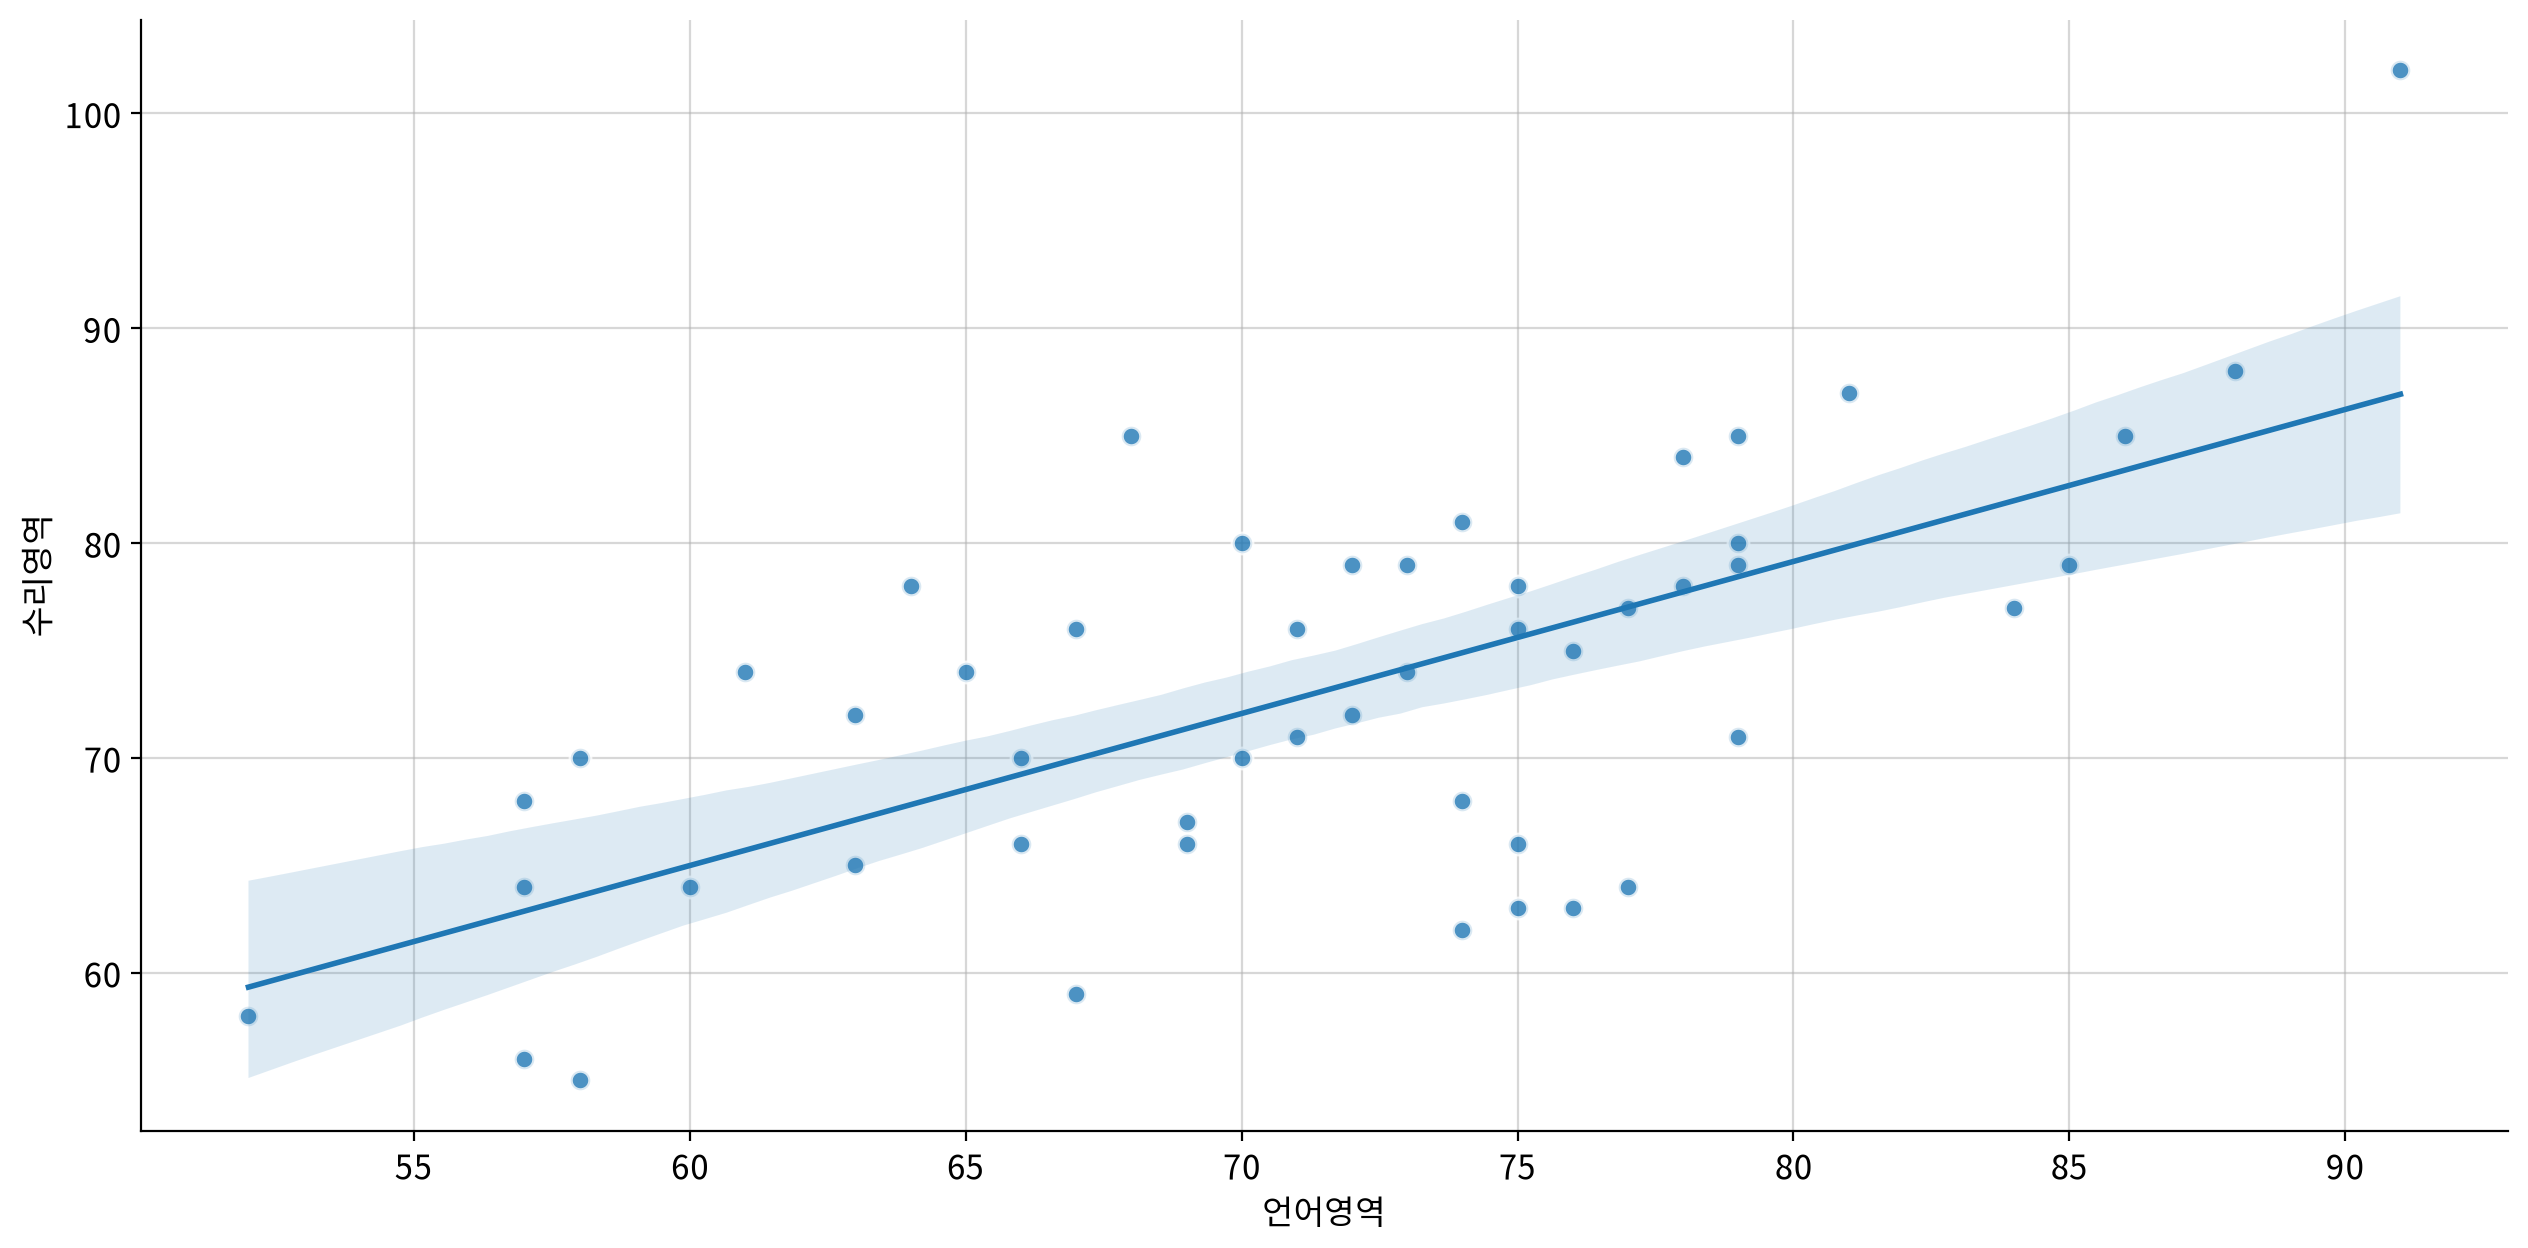

In [3]:
my_plot.lmplot(origin, x='언어영역', y='수리영역')

> 인사이트
> - 언어영역 점수가 높을 수록 수리영역 점수도 함께 높아지는 경향이 있음
> - 두 변수는 대체로 직선적인 관계를 보임
> - 다만 점들이 넓게 퍼져 있어 관계가 아주 강하다고 보긴 어려움
> - 일부 벗어난 점도 보여서 해석할 때 같이 봐야 함

### #03 공분산

- 파이썬에서는 numpy 패키지의 **cov() 함수**를 사용하여 공분산 값을 구할 수 있다.
    - 2차원 배열이 리턴되는데 이 중에서 공분산 값은 **0행1열** 혹은 **1행0열**의 값이다.
- 공분산은 상관관계의 상승 혹은 하강하는 경향을 이해할 수는 있으나 2개 변수의 측정 단위의 크기에 따라 값이 달라지므로 **절대적 정도를 파악하기에는 한계**가 있다.
    - 결과값이 양수면 정비례, 음수면 반비례

In [5]:
c = np.cov(origin['언어영역'], origin['수리영역'])
c

array([[76.86693878, 54.39020408],
       [54.39020408, 85.57714286]])

### #04 상관분석

#### 1. 피어슨 상관계수

| \|r\| 구간          | 강도 (통일 용어)    |
| ----------------- | ------------- |
| \|r\| > 0.7       | Strong (강함)   |
| 0.3 < \|r\| ≤ 0.7 | Moderate (중간) |
| 0 < \|r\| ≤ 0.3   | Weak (약함)     |
| r ≈ 0             | None (없음)     |

In [6]:
pearson_r, pearson_p = pearsonr(origin['언어영역'], origin['수리영역'])
print(f"Pearson correlation coefficient: {pearson_r:.4f}, p-value: {pearson_p:.4f}")

Pearson correlation coefficient: 0.6706, p-value: 0.0000


> - 피어슨 상관계수 0.6706으로, 두 변수는 양의 상관관계가 있음
> - p-value가 0.0000이라 통계적으로 유의함
> - 상관 정도는 위 강도 기준표에 따라 중간(Moderate) 수준임 (|r|이 0.7을 넘지 않음)

#### 2. 스피어만 상관계수

In [8]:
spearman_r, spearman_p = spearmanr(origin['언어영역'], origin['수리영역'])
print(f"Spearman correlation coefficient: {spearman_r:.4f}, p-value: {spearman_p:.4f}")

Spearman correlation coefficient: 0.5991, p-value: 0.0000


> - 스피어만 상관계수 0.5991로, 두 변수는 양의 상관관계가 있음
> - p-value가 0.0000이라 통계적으로 유의함
> - 순위 기준으로도 중간 정도의 관련성이 보임

#### 3. 상관행렬

- 여러 변수들 간의 상관계수를 한 눈에 볼 수 있도록 정리한 표
    - 행과 열에 같은 변수들이 배치
    - 대각선 값은 항상 1
    - 대칭 행렬 (A와 B의 상관계수 = B와 A의 상관계수)

In [9]:
# 분석 대상 변수명 정의 (이후 셀에서 공통으로 사용)
xname = '언어영역'
yname = '수리영역'

# method='pearson' or 'spearman'
corr_matrix = origin[[xname, yname]].corr(method='pearson')
corr_matrix

,언어영역,수리영역
언어영역,1.000,0.671
수리영역,0.671,1.000


#### 4. 상관계수 히트맵

- 상관행렬을 시각화한 그래프

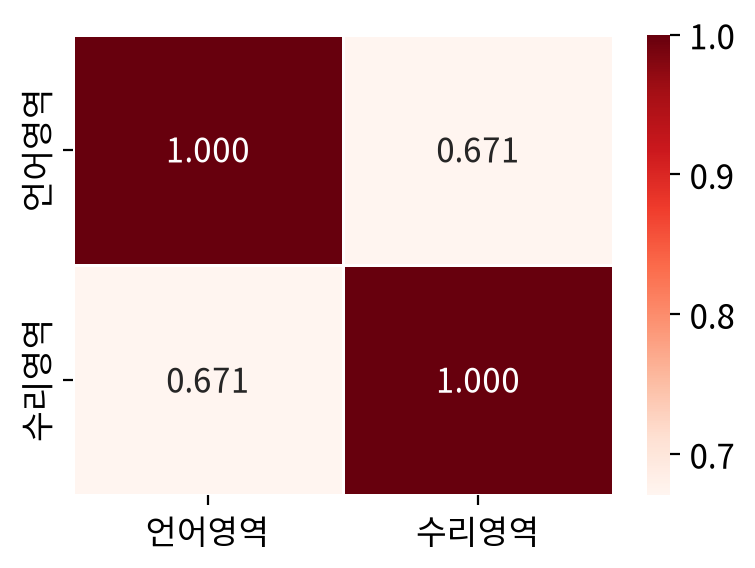

In [10]:
my_plot.heatmap(corr_matrix, width=400, height=300,
                palette='Reds', annot=True, fmt=".3f")

#### 5. 상관행렬에 직접 배경색상 적용

In [11]:
corr_matrix.style.background_gradient(cmap='Reds')

,언어영역,수리영역
언어영역,1.000000,0.670613
수리영역,0.670613,1.000000
